# VardiyaWatt ML
## Kısa vadeli endüstriyel enerji tahmininde model karşılaştırması
**Hazırlayan: Görkem Vatansever**

Colab: `Çalışma zamanı > Tümünü çalıştır`. GPU gerekmez. CSV bulunamazsa resmi UCI kaynağından indirilir.
Tüm çıktılar gerçek kod çalıştırmasıyla üretilmiştir. Yönergedeki ML seçeneği uygulanmıştır.


## 1 Problem ve veri
Amaç, geçmiş tüketim ve takvim bilgisinden bir sonraki 15 dakikalık dönemin enerjisini (kWh) tahmin etmektir.
Veri UCI Steel Industry Energy Consumption (DAEWOO Steel, Güney Kore), 35.040 gerçek kayıttır.
Kaynak: https://doi.org/10.24432/C52G8C . Lisans: CC BY 4.0.
Eksik/tekrar kontrolü ve gece yarısı zaman düzeltmesi aşağıda uygulanır.

In [1]:
"""UCI enerji verisiyle zaman sıralı doğrulama ve Random Forest karşılaştırması."""
from pathlib import Path
import io, zipfile, urllib.request, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn import __version__ as sklearn_version
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

OUT=Path(globals().get('PROJECT_OUTPUT','ciktilar'))
OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,
                     'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':120})
COLOR='#167D8D'; ORANGE='#BD7F3F'; DARK='#213D4C'
SOURCE_URL='https://archive.ics.uci.edu/static/public/851/steel+industry+energy+consumption.zip'
paths=[Path('Steel_industry_data.csv'),Path('../public/data/steel-industry.csv'),
       Path('data/Steel_industry_data.csv')]
existing=next((p for p in paths if p.exists()),None)
if existing:
    source_bytes=existing.read_bytes()
else:
    with urllib.request.urlopen(SOURCE_URL,timeout=60) as response:
        archive=zipfile.ZipFile(io.BytesIO(response.read()))
        source_bytes=archive.read('Steel_industry_data.csv')
raw=pd.read_csv(io.BytesIO(source_bytes))
print('Ham boyut:',raw.shape,'Eksik:',int(raw.isna().sum().sum()),'Tekrar:',int(raw.duplicated().sum()))
assert not raw.isna().any().any()
data=raw.drop_duplicates().copy()
time=pd.to_datetime(data['date'],format='%d/%m/%Y %H:%M')
midnight=data.NSM.eq(0)
time+=pd.to_timedelta(midnight.astype(int),unit='D')
data.index=pd.DatetimeIndex(time)
assert data.index.is_unique and data.index.to_series().diff().dropna().eq(pd.Timedelta(minutes=15)).all()
assert data.Usage_kWh.ge(0).all()



Ham boyut: (35040, 11) Eksik: 0 Tekrar: 0


## 2 Özellikler ve zaman sıralı bölme
Girdiler: 15 dakika, 1 saat ve 24 saat önceki dönem tüketimi, hedef saatin sinüs/kosinüsü ve hafta sonu göstergesi.
Hedef dönemin CO₂, reaktif enerji, güç faktörü ve yük sınıfı kullanılmaz. İlk 96 satır geçmiş olmadığı için çıkarılır.
İlk %60 eğitim, sonraki %20 validation, son %20 testtir. Veri rastgele karıştırılmaz.

In [2]:
# Altı girdinin tümü hedef dönem başlamadan bilinen bilgiden oluşur.
features=pd.DataFrame(index=data.index)
for lag in [1,4,96]:features[f'lag_{lag}']=data.Usage_kWh.shift(lag)
hour=data.index.hour+data.index.minute/60
features['hour_sin']=np.sin(2*np.pi*hour/24)
features['hour_cos']=np.cos(2*np.pi*hour/24)
features['weekend']=(data.index.dayofweek>=5).astype(int)
features['target_kwh']=data.Usage_kWh
features=features.dropna()
X=features.drop(columns='target_kwh');y=features.target_kwh
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=.2,shuffle=False)
X_train,X_val,y_train,y_val=train_test_split(X_dev,y_dev,test_size=.25,shuffle=False)
print('Eğitim / validation / test:',len(X_train),len(X_val),len(X_test))



Eğitim / validation / test: 20966 6989 6989


## 3 Metrikler ve aykırı değer politikası
Ana seçim ölçütü MAE'dir. MSE, RMSE ve R² tamamlayıcıdır. R² doğruluk yüzdesi değildir.
IQR sınırları yalnız ilk eğitim parçasından hesaplanır. Geçerli üretim tepelerini kaybetmemek için
sınır dışındaki satırlar otomatik silinmez veya kırpılmaz. Bir regresyon problemi olduğu için sınıf dengesizliği işlemi uygulanmaz.

In [3]:
def score(truth,prediction):
    return {'MAE':float(mean_absolute_error(truth,prediction)),
            'MSE':float(mean_squared_error(truth,prediction)),
            'RMSE':float(np.sqrt(mean_squared_error(truth,prediction))),
            'R2':float(r2_score(truth,prediction))}

# Sınırlar yalnız ilk eğitim parçasından öğrenilir; testte aykırı satır silinmez.
q1,q3=y_train.quantile([.25,.75]);iqr=float(q3-q1)
outlier_low=float(q1-1.5*iqr);outlier_high=float(q3+1.5*iqr)
outlier_count=int(((y_train<outlier_low)|(y_train>outlier_high)).sum())
# Büyük tüketimler üretimin gerçek tepe noktaları olabilir. Otomatik kesme/silme yok.



## 4 Modeller ve validation ile hiperparametre seçimi
Son ölçüm referansı, StandardScaler + LinearRegression ve RandomForestRegressor karşılaştırılır.
Scaler yalnız eğitim bölümünde öğrenilir. Orman için ölçekleme gerekmez. Ormanda 80 ağaç, bootstrap=True,
max_features=1.0, random_state=42 sabittir. max_depth=[8,16] ve min_samples_leaf=[5,20] toplam dört aday oluşturur.
En düşük validation MAE, ormanın ayarını belirler. Bu adım test kümesini kullanmaz.

In [4]:
lin=make_pipeline(StandardScaler(),LinearRegression()).fit(X_train,y_train)
validation_rows=[{'model':'Son ölçüm referansı',**score(y_val,X_val.lag_1)},
                 {'model':'Doğrusal regresyon',**score(y_val,np.maximum(lin.predict(X_val),0))}]
search=[]
for depth in [8,16]:
    for leaf in [5,20]:
        estimator=RandomForestRegressor(n_estimators=80,max_depth=depth,min_samples_leaf=leaf,
                                       max_features=1.0,bootstrap=True,random_state=42,n_jobs=4)
        estimator.fit(X_train,y_train)
        result={'max_depth':depth,'min_samples_leaf':leaf,
                **score(y_val,estimator.predict(X_val))}
        search.append(result)
        print('Validation:',result,flush=True)
best=min(search,key=lambda r:r['MAE'])
validation_rows.append({'model':'Random Forest',**{k:best[k] for k in ['MAE','MSE','RMSE','R2']}})



Validation: {'max_depth': 8, 'min_samples_leaf': 5, 'MAE': 4.494159535902205, 'MSE': 92.15346505664591, 'RMSE': 9.599659632333113, 'R2': 0.9063105529857232}
Validation: {'max_depth': 8, 'min_samples_leaf': 20, 'MAE': 4.616633319927479, 'MSE': 95.70463299059652, 'RMSE': 9.78287447484616, 'R2': 0.9027001954177016}
Validation: {'max_depth': 16, 'min_samples_leaf': 5, 'MAE': 4.382266149721323, 'MSE': 89.03622360970577, 'RMSE': 9.435900784223294, 'R2': 0.9094797515307186}
Validation: {'max_depth': 16, 'min_samples_leaf': 20, 'MAE': 4.547871117160234, 'MSE': 93.82434825658392, 'RMSE': 9.686296932088336, 'R2': 0.90461182008478}


## 5 Sabitlenen modelin test değerlendirmesi
Seçilen orman ve doğrusal model ilk %80'in tamamında yeniden eğitilir. Son %20'de tahmin yapılır.
Her test adımında daha önce gerçekleşmiş tüketim ölçümleri bilinir. Bu, sürekli yenilenen tek adım ileri tahmindir.
Test sonucu sonrasında yeni parametre araması yapılmaz.

In [5]:
# Hiperparametreler sabitlendi. Seçilen model geliştirme verisinin tamamında yeniden eğitilir.
rf=RandomForestRegressor(n_estimators=80,max_depth=best['max_depth'],
                        min_samples_leaf=best['min_samples_leaf'],max_features=1.0,
                        bootstrap=True,random_state=42,n_jobs=4).fit(X_dev,y_dev)
lr=make_pipeline(StandardScaler(),LinearRegression()).fit(X_dev,y_dev)
pred_rf=rf.predict(X_test);pred_lr=np.maximum(lr.predict(X_test),0)
pred_base=X_test.lag_1.to_numpy()
metrics=pd.DataFrame([{'model':'Son ölçüm referansı',**score(y_test,pred_base)},
                      {'model':'Doğrusal regresyon',**score(y_test,pred_lr)},
                      {'model':'Random Forest',**score(y_test,pred_rf)}])
train_scores={'Random Forest':score(y_dev,rf.predict(X_dev)),
              'Doğrusal regresyon':score(y_dev,np.maximum(lr.predict(X_dev),0))}
print('Son test sonuçları:\n',metrics.round(5).to_string(index=False),flush=True)
test=pd.DataFrame({'gercek_kwh':y_test,'rf_kwh':pred_rf,'lr_kwh':pred_lr,'referans_kwh':pred_base})
test['mutlak_hata']=np.abs(test.gercek_kwh-test.rf_kwh)



Son test sonuçları:
               model     MAE       MSE     RMSE      R2
Son ölçüm referansı 5.44745 152.06453 12.33144 0.84571
 Doğrusal regresyon 6.60377 134.79294 11.61004 0.86323
      Random Forest 4.09077  74.64887  8.63996 0.92426


## 6 Hata analizi
Yüksek tüketim eşiği ve ani değişim eşiği ilk eğitim parçasından hesaplanır.
Ani değişim grubunu oluştururken gerçek hedef kullanılır; bu yalnız geriye dönük hata teşhisidir,
gelecekte kullanılabilecek bir girdi veya önceden bilinen alarm değildir. En büyük beş hata ayrıca kaydedilir.

In [6]:
# Sonuç sonrası hata teşhisi: gerçek hedef farkı ileriye dönük model girdisi değildir.
change_limit=float(np.quantile(np.abs(y_train-X_train.lag_1),.90))
high_limit=float(y_train.quantile(.75))
groups=[]
for name,mask in [('Düşük/orta tüketim',y_test<=high_limit),('Yüksek tüketim',y_test>high_limit),
                  ('Sakin dönem',np.abs(y_test-X_test.lag_1)<=change_limit),
                  ('Ani değişim',np.abs(y_test-X_test.lag_1)>change_limit)]:
    groups.append({'grup':name,'n':int(mask.sum()),'RF_MAE':float(np.abs(y_test[mask]-pred_rf[mask]).mean()),
                   'Referans_MAE':float(np.abs(y_test[mask]-pred_base[mask]).mean())})
worst=test.nlargest(5,'mutlak_hata').reset_index()



## 7 Veri keşfi ve değerlendirme grafikleri
En az üç anlamlı keşif: tüketim dağılımı, saate göre ortalama ve geçmiş dönemle ilişki.
Ek olarak model MAE karşılaştırması, testin ilk 48 saati ve hata grupları çizilir.
Keşif grafikleri tüm veriyi betimler; model ayarı için test verisi kullanılmaz.

In [7]:
# EDA: birbirinden farklı üç veri ilişkisi, etiketli ve birimli eksenlerle.
hour_means=data.groupby(data.index.hour).Usage_kWh.mean()
weekday_mean=float(data.loc[data.index.dayofweek<5,'Usage_kWh'].mean())
weekend_mean=float(data.loc[data.index.dayofweek>=5,'Usage_kWh'].mean())
corr=float(features.lag_1.corr(features.target_kwh))
fig,axes=plt.subplots(3,1,figsize=(8,8.1),gridspec_kw={'hspace':.65})
axes[0].hist(data.Usage_kWh,bins=45,color=COLOR,alpha=.9)
axes[0].set(title='1. Dönemlik enerji tüketiminin dağılımı',xlabel='Enerji (kWh / 15 dakika)',ylabel='Kayıt sayısı')
axes[1].bar(hour_means.index,hour_means.values,color=COLOR)
axes[1].set(title='2. Saate göre ortalama dönem enerjisi',xlabel='Günün saati',ylabel='Ortalama enerji (kWh)')
axes[1].set_xticks(range(0,24,2))
axes[2].scatter(features.lag_1,features.target_kwh,s=5,alpha=.15,color=COLOR,rasterized=True)
axes[2].set(title=f'3. Önceki dönemle ilişki (Pearson r = {corr:.3f})',xlabel='Önceki dönemin enerjisi (kWh)',ylabel='Hedef dönem (kWh)')
fig.savefig(OUT/'01_eda.png',dpi=170,bbox_inches='tight');plt.close(fig)

fig,ax=plt.subplots(figsize=(8,3.1))
bars=ax.barh(metrics.model,metrics.MAE,color=[ORANGE,'#728F9B',COLOR])
ax.bar_label(bars,fmt='%.2f kWh',padding=6)
ax.set(xlabel='MAE (kWh, düşük daha iyi)',title='Aynı test kümesinde ortalama mutlak hata',xlim=(0,float(metrics.MAE.max())*1.3))
fig.tight_layout();fig.savefig(OUT/'02_mae.png',dpi=170);plt.close(fig)

fig,ax=plt.subplots(figsize=(8,3.1));window=test.iloc[:192]
ax.plot(np.arange(len(window))/4,window.gercek_kwh,color=DARK,label='Gerçek',lw=1.5)
ax.plot(np.arange(len(window))/4,window.rf_kwh,color=COLOR,label='Random Forest',lw=1.3)
ax.plot(np.arange(len(window))/4,window.referans_kwh,color=ORANGE,label='Son ölçüm referansı',lw=.8,alpha=.7)
ax.set(title='Testin ilk 48 saatinde tek adım ileri tahmin',xlabel='Test başlangıcından itibaren saat',ylabel='Dönem enerjisi (kWh)')
ax.legend(frameon=False,fontsize=8,ncol=3);fig.tight_layout();fig.savefig(OUT/'03_test_penceresi.png',dpi=170);plt.close(fig)

fig,ax=plt.subplots(figsize=(8,3));g=pd.DataFrame(groups);pos=np.arange(len(g))
ax.bar(pos-.17,g.RF_MAE,width=.34,label='Random Forest',color=COLOR)
ax.bar(pos+.17,g.Referans_MAE,width=.34,label='Son ölçüm referansı',color=ORANGE)
ax.set_xticks(pos,g.grup);ax.set(ylabel='MAE (kWh)',title='Hata hangi çalışma koşullarında artıyor?')
ax.legend(frameon=False,fontsize=8);fig.tight_layout();fig.savefig(OUT/'04_hata_gruplari.png',dpi=170);plt.close(fig)



## 8 Yeniden üretilebilir çıktılar
CSV tabloları ve sonuclar.json, raporda kullanılan sayıları içerir. Tek tesis/yıl ve ani rejim değişimleri
genellenebilirliği sınırlar. Yürüyen zaman doğrulaması ve önceden bilinen üretim planı eklenmesi sonraki adımdır.
Bu çalışma saha tasarrufu veya kalibre edilmiş tahmin aralığı ölçmez.

In [8]:
metrics.to_csv(OUT/'test_metrikleri.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(search).to_csv(OUT/'validation_arama.csv',index=False,encoding='utf-8-sig')
test.to_csv(OUT/'test_tahminleri.csv',encoding='utf-8-sig')
pd.DataFrame(groups).to_csv(OUT/'hata_gruplari.csv',index=False,encoding='utf-8-sig')
worst.to_csv(OUT/'en_buyuk_5_hata.csv',index=False,encoding='utf-8-sig')
summ={'raw_rows':len(raw),'raw_cols':len(raw.columns),'model_rows':len(features),
      'train_rows':len(X_train),'val_rows':len(X_val),'test_rows':len(X_test),
      'train_start':str(X_train.index.min()),'train_end':str(X_train.index.max()),
      'val_start':str(X_val.index.min()),'val_end':str(X_val.index.max()),
      'test_start':str(X_test.index.min()),'test_end':str(X_test.index.max()),
      'source_sha256':hashlib.sha256(source_bytes).hexdigest(),
      'source_url':SOURCE_URL,'midnight_corrected':int(midnight.sum()),
      'target_summary':data.Usage_kWh.describe().to_dict(),'correlation':corr,
      'weekday_mean':weekday_mean,'weekend_mean':weekend_mean,
      'peak_hour':int(hour_means.idxmax()),'peak_hour_mean':float(hour_means.max()),
      'initial_train_outlier_bounds':[outlier_low,outlier_high],
      'initial_train_outlier_count':outlier_count,
      'best':best,'search':search,'validation':validation_rows,
      'metrics':metrics.to_dict(orient='records'),'training_metrics':train_scores,
      'change_limit':change_limit,'high_limit':high_limit,'groups':groups,
      'worst':json.loads(worst.to_json(orient='records',date_format='iso')),
      'python_version':platform.python_version(),'sklearn_version':sklearn_version,
      'numpy_version':np.__version__,'pandas_version':pd.__version__}
(OUT/'sonuclar.json').write_text(json.dumps(summ,ensure_ascii=False,indent=2),encoding='utf-8')
print('Grafikler ve sonuç dosyaları hazır.',flush=True)


Grafikler ve sonuç dosyaları hazır.


## Çalıştırılan grafikler


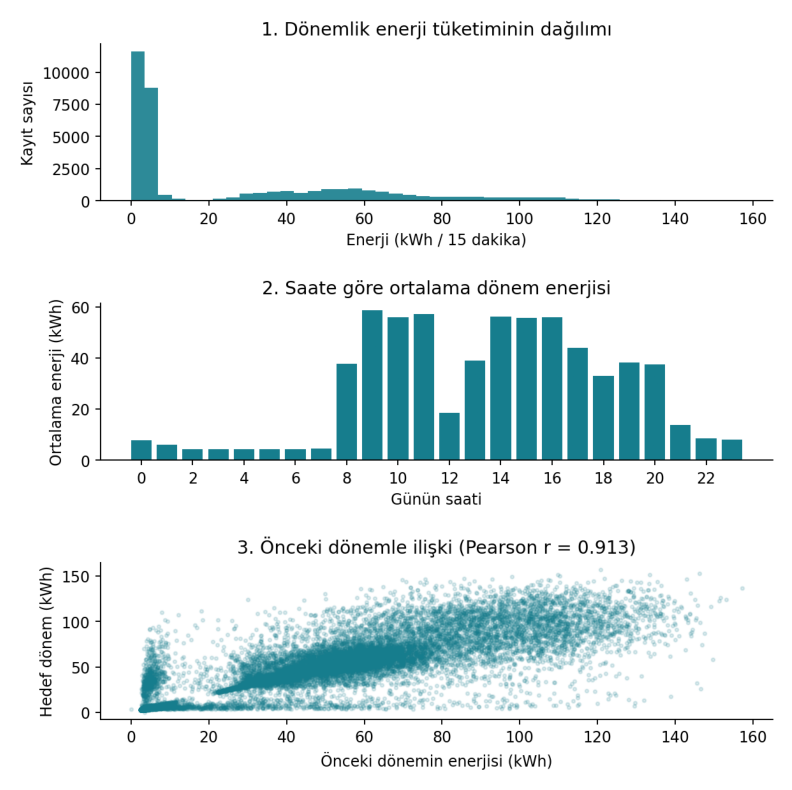

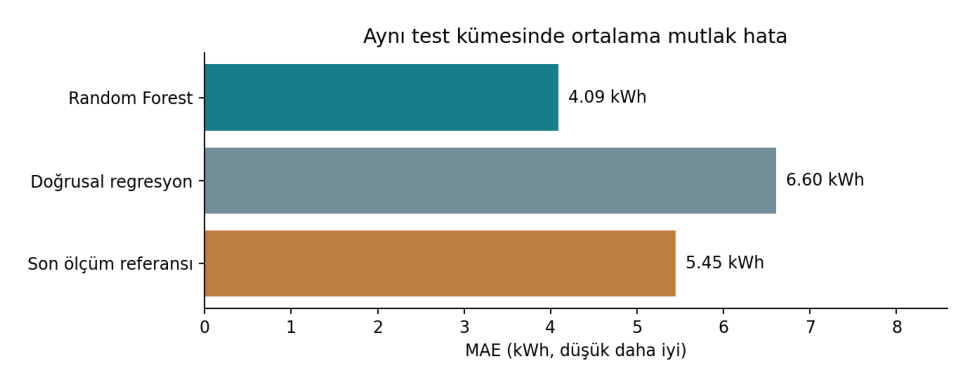

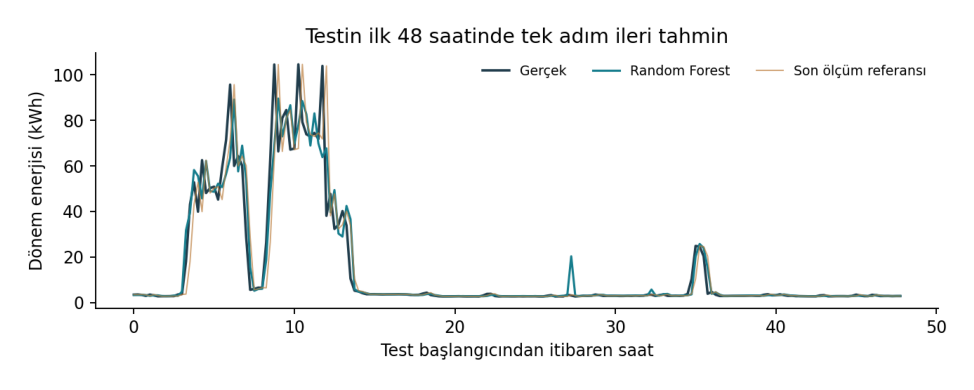

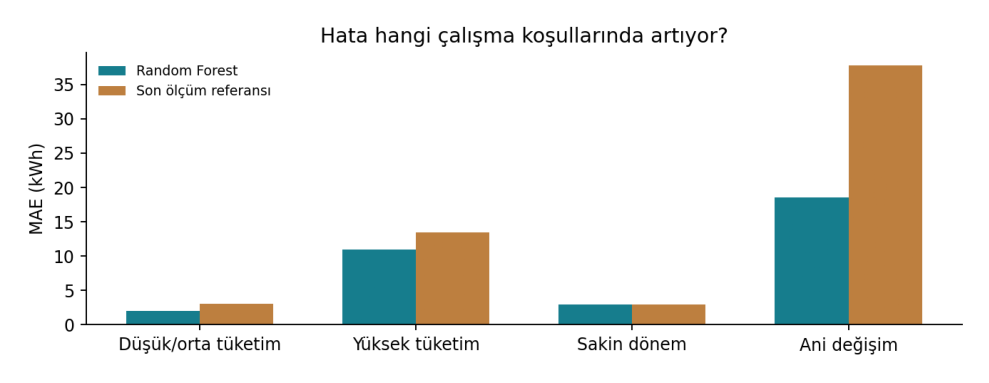

In [9]:
for filename in ['01_eda.png','02_mae.png','03_test_penceresi.png','04_hata_gruplari.png']:
    fig, ax = plt.subplots(figsize=(10,8 if filename=='01_eda.png' else 4))
    ax.imshow(plt.imread(OUT / filename)); ax.axis('off'); fig.tight_layout(); plt.show()
